# 02 - Business Analysis
Cross-functional analysis. Each section ends with **Observation -> Evidence -> Why -> Impact -> Action**.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.float_format", "{:,.3f}".format)
import analysis as A, modeling as M, visuals as V
from utils import fmt_egp, fmt_pct, fmt_int

In [2]:
import run_pipeline as RP
d = A.load_all()
R = RP.build_results(d)
s = d["sales"]

## 1. Revenue and profitability

In [3]:
R['kpi_fy'][['Fiscal_Year','Net_Sales','Gross_Profit','Gross_Margin','Units','Invoices','Avg_Discount','AOV','Refund_Rate']]

,Fiscal_Year,Net_Sales,Gross_Profit,Gross_Margin,Units,Invoices,Avg_Discount,AOV,Refund_Rate
0,FY24,"129,524,345.150","19,805,835.800",0.153,510545,53523,0.299,"2,419.975",0.023
1,FY25,"143,508,088.680","22,018,781.250",0.153,565872,60441,0.298,"2,374.350",0.023
2,FY26,"148,305,943.700","23,063,672.850",0.156,584172,66036,0.296,"2,245.835",0.021


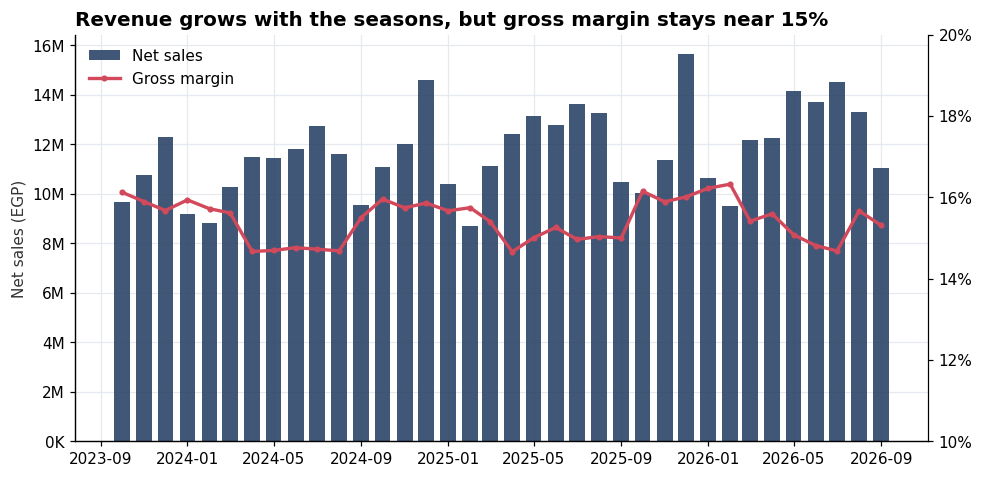

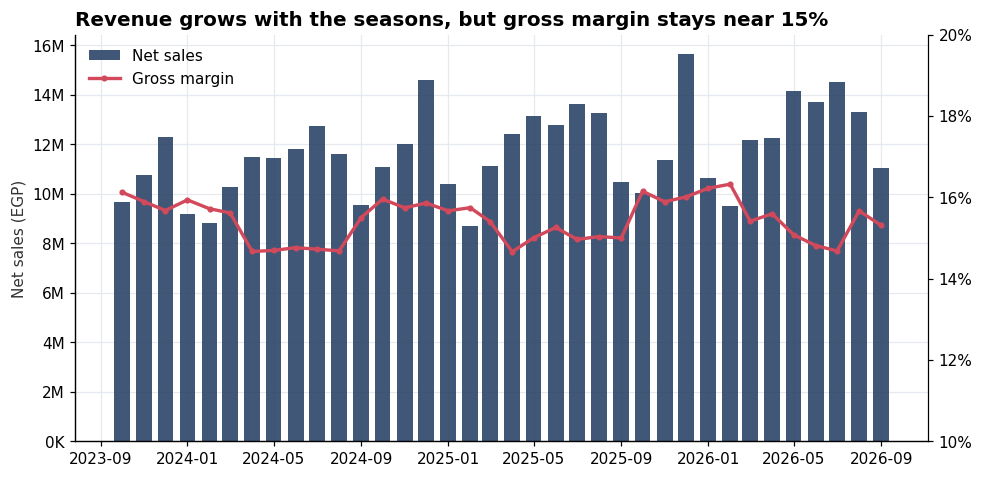

In [4]:
V.revenue_margin_trend(R['monthly'])

**Observation:** Net sales grew +10.8% in FY25 but only +3.3% in FY26 (EGP 129.5M -> 143.5M -> 148.3M). Gross margin barely moved: 15.3% -> 15.6%.
**Evidence:** group GP EGP 64.9M on EGP 421.3M sales; GP growth FY26 +4.7%.
**Why:** 85% of revenue is wholesale at 11.9% margin (next section).
**Impact:** growth is not converting into profit at the rate management expects; each extra EGP of wholesale revenue earns 12 piasters.
**Action:** manage the business on gross profit, not revenue (see opportunity in notebook 04).

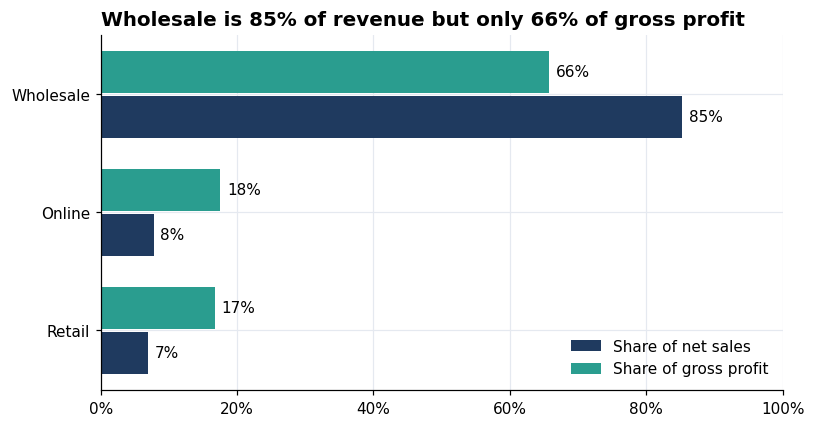

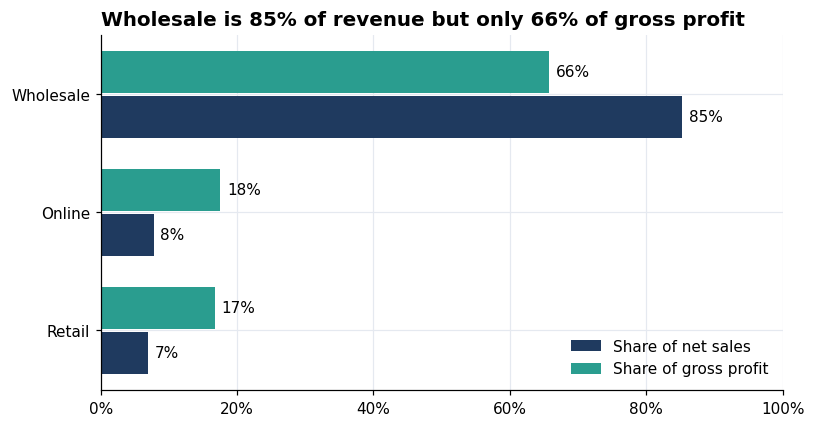

In [5]:
V.channel_share_revenue_vs_profit(R['channel_scorecard'])

In [6]:
R['channel_scorecard'][['Channel','Net_Sales','Net_Share','Gross_Profit','GP_Share','Gross_Margin','GP_per_Unit','Avg_Discount']]

,Channel,Net_Sales,Net_Share,Gross_Profit,GP_Share,Gross_Margin,GP_per_Unit,Avg_Discount
0,Online,"32,629,574.450",0.077,"11,384,070.740",0.175,0.349,114.598,0.088
1,Retail,"29,347,687.400",0.070,"10,869,176.780",0.168,0.370,126.131,0.056
2,Wholesale,"359,361,115.680",0.853,"42,635,042.380",0.657,0.119,28.904,0.326


**Observation:** wholesale = 85% of sales but 66% of profit; online + retail = 15% of sales and 34% of profit. **Why:** unit cost is the same in all channels (~EGP 214); wholesale simply sells at a 32.6% average discount versus 5-9% elsewhere.

## 2. Seasonality and product contribution

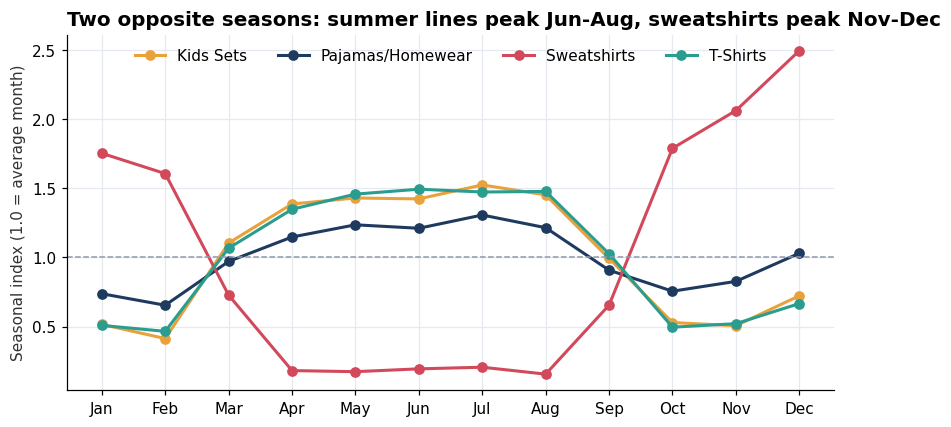

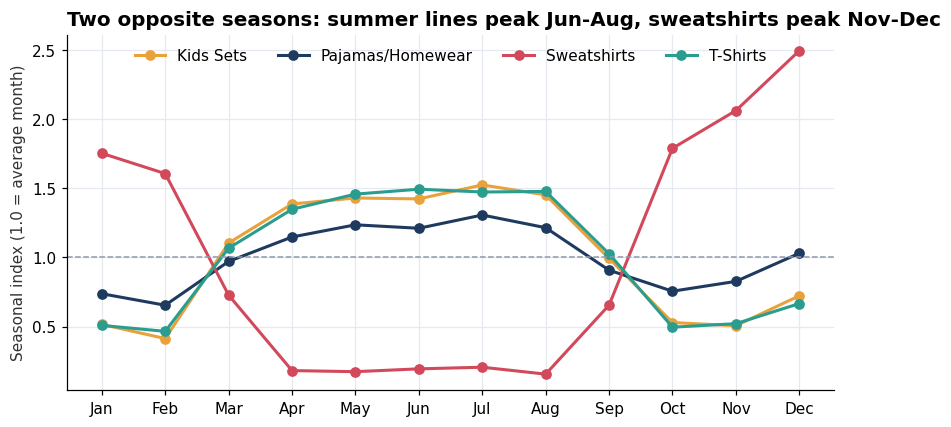

In [7]:
V.seasonality_by_group(R['seasonality'])

**Observation:** two opposite seasons - summer lines peak Jun-Aug, sweatshirts (and autumn pajamas) peak Nov-Dec. **Action:** replenishment and marketing calendars must be run per season group (the forecast in case 4 does this).

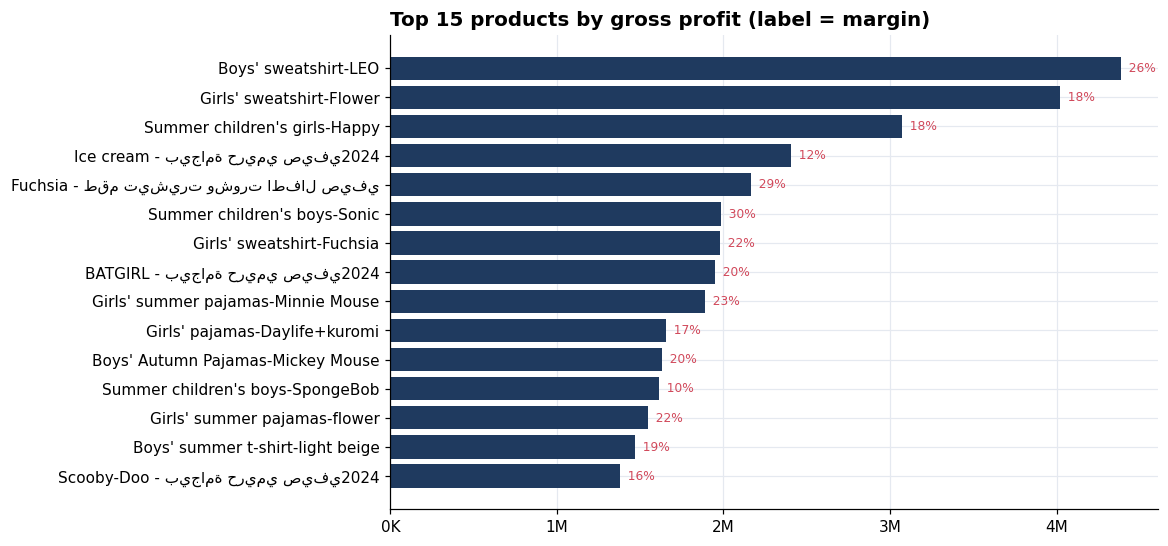

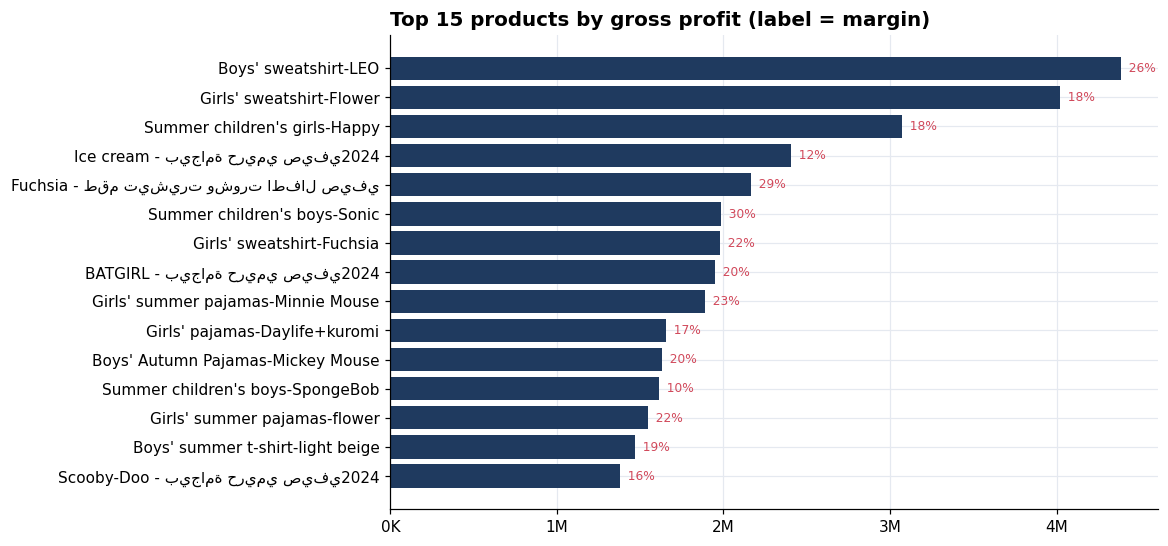

In [8]:
V.product_gp_contribution(R['product_contribution'])

In [9]:
R['product_contribution'].groupby('ABC_by_GP').agg(Products=('Product_ID','count'), GP_Share=('GP_Share','sum')).join(R['product_contribution'].groupby('Product_Family').size().rename('x'), how='left').drop(columns='x')

,Products,GP_Share
ABC_by_GP,,
A,33,0.806
B,16,0.150
C,10,0.044


33 of 59 products generate 80% of gross profit. Sweatshirts have the best family margin (17.9%) and the largest single contributors; T-shirts the weakest (13.1%).

## 3. Discount impact - the biggest profit driver

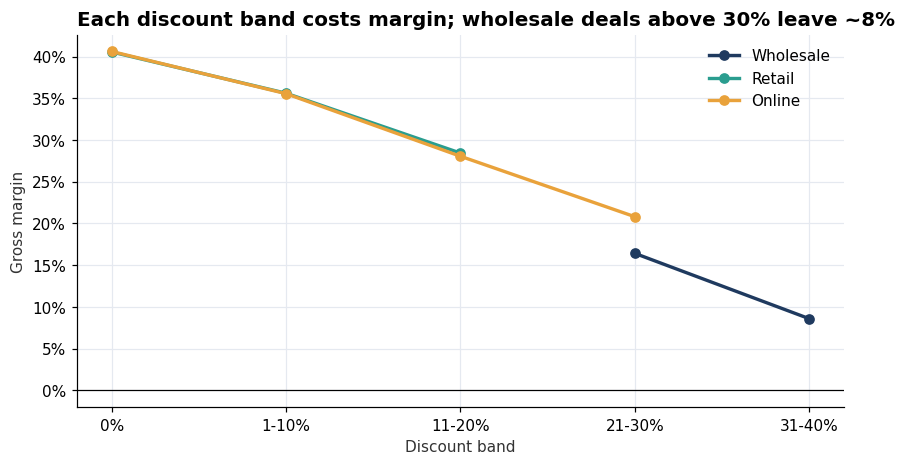

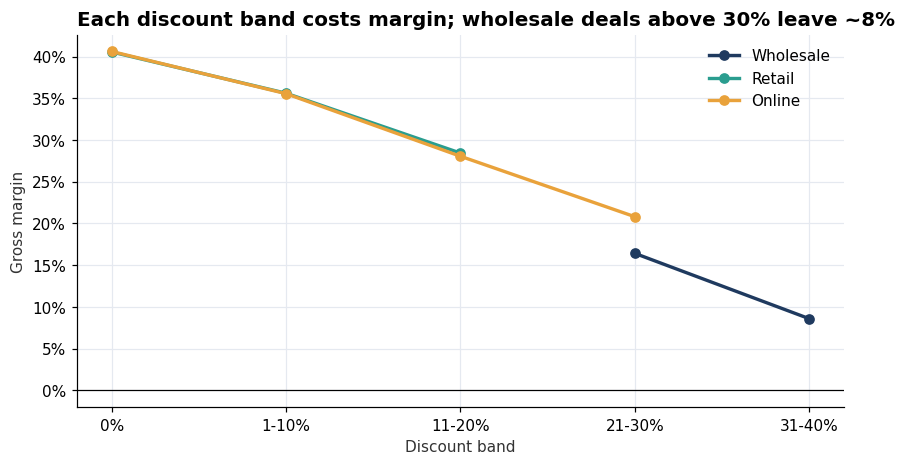

In [10]:
V.discount_band_margin(R['discount_impact'])

In [11]:
R['discount_leakage']

,Channel,Gross,Net,COGS,Discount_Given,Margin_Before_Discount,Share_of_Margin_Given_Away
0,Online,35766917,"32,629,574.450","21,245,503.710","3,137,342.550","14,521,413.290",0.216
1,Retail,31094146,"29,347,687.400","18,478,510.620","1,746,458.600","12,615,635.380",0.138
2,Wholesale,533230998,"359,361,115.680","316,726,073.300","173,869,882.320","216,504,924.700",0.803


In [12]:
R['promo_test']

,Year,Discount_Promo,Discount_Ref,Units_per_Day_Promo,Units_per_Day_Ref,GP_per_Unit_Promo,GP_per_Unit_Ref,Volume_Lift,GP_per_Day_Change
0,2024,0.068,0.071,175.885,166.339,115.777,115.181,0.057,0.063
1,2025,0.071,0.071,203.344,191.935,115.713,115.439,0.059,0.062
2,2026,0.097,0.073,230.820,219.419,106.050,114.633,0.052,-0.027


**Observation:** wholesale gave away EGP 173.9M of discount = **80% of its pre-discount margin**; 4,876 invoices (10.4% of wholesale) were sold below cost (EGP -1.37M).
**Evidence on promotions:** the Jun-Jul 2026 retail/online promo raised the discount from 7.3% to 9.7%, yet volume lift versus May/Aug was +5.2% - the same as in 2024 and 2025 when no extra discount was given (+5.7%, +5.9%). Gross profit per day moved -2.7% instead of +6%.
**Why:** discounts are not buying incremental volume.
**Action:** stop untargeted promotions; govern wholesale discounts (notebook 04).

## 4. Customers

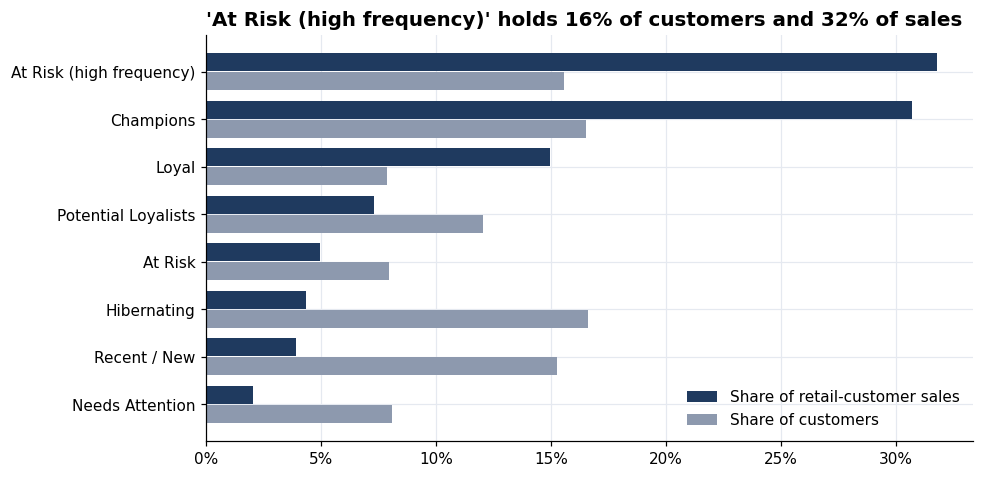

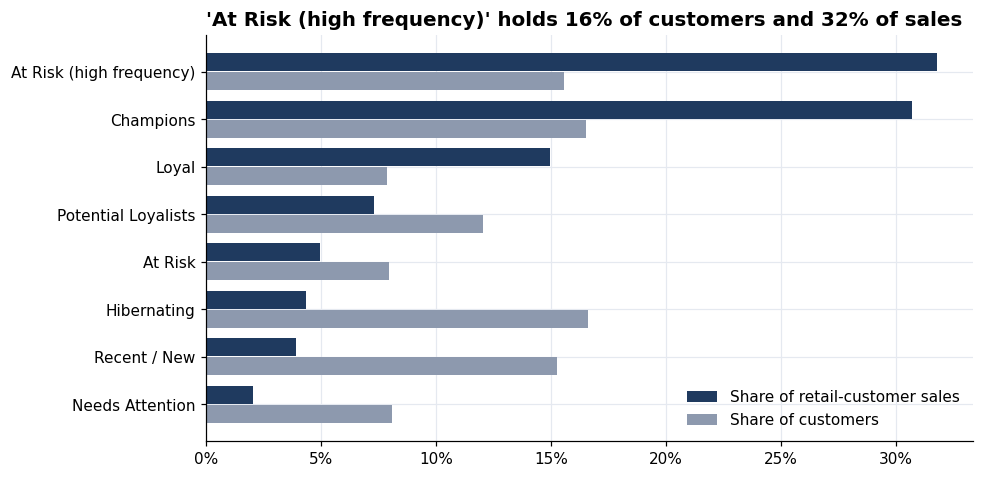

In [13]:
V.rfm_share(R['rfm_segments'])

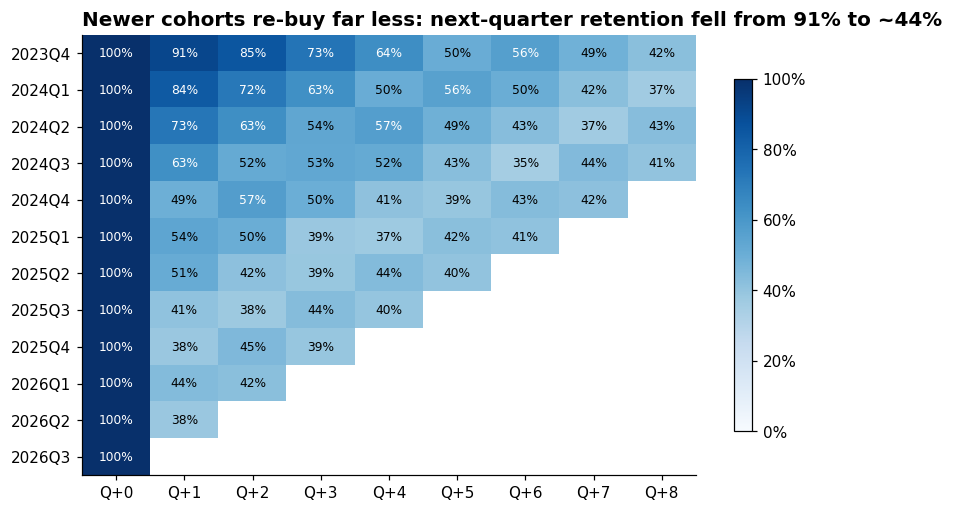

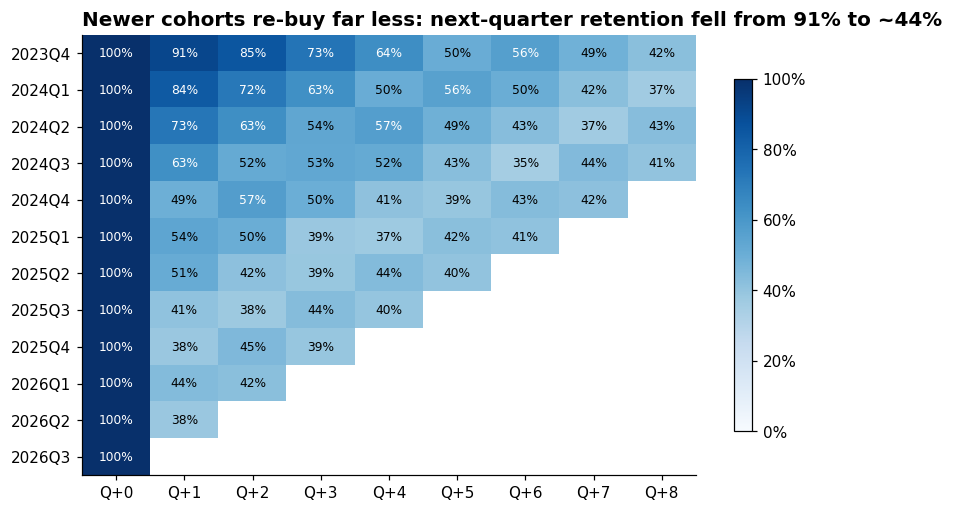

In [14]:
V.cohort_heatmap(R['cohorts'])

**Observation:** 83.5% of retail customers repeat, but 'At Risk (high frequency)' customers (3,745; 15.6% of customers) contribute 31.8% of retail-customer sales and have been silent for a median 229 days. Next-quarter retention of new cohorts fell from 91% (Q4-2023) to ~44% (2025+ cohorts).
**Why:** acquisition channel does not differentiate quality (repeat 82-84% in all channels), so the decline is in post-purchase engagement, not in who is acquired.
**Action:** automated win-back journeys for the 3,745 at-risk customers (65% are opted-in) and onboarding for new cohorts.

## 5. Inventory

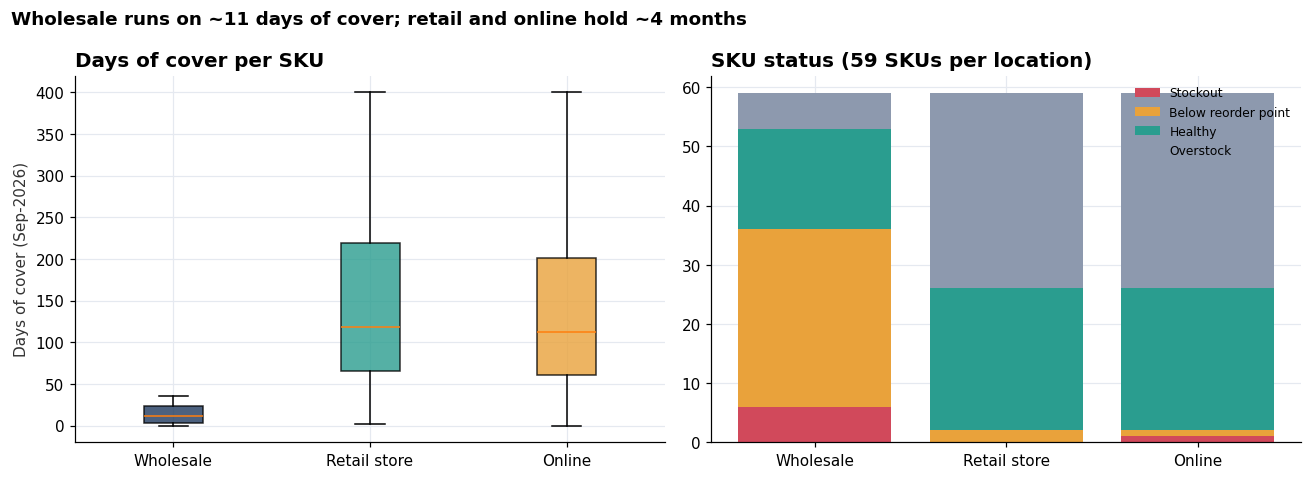

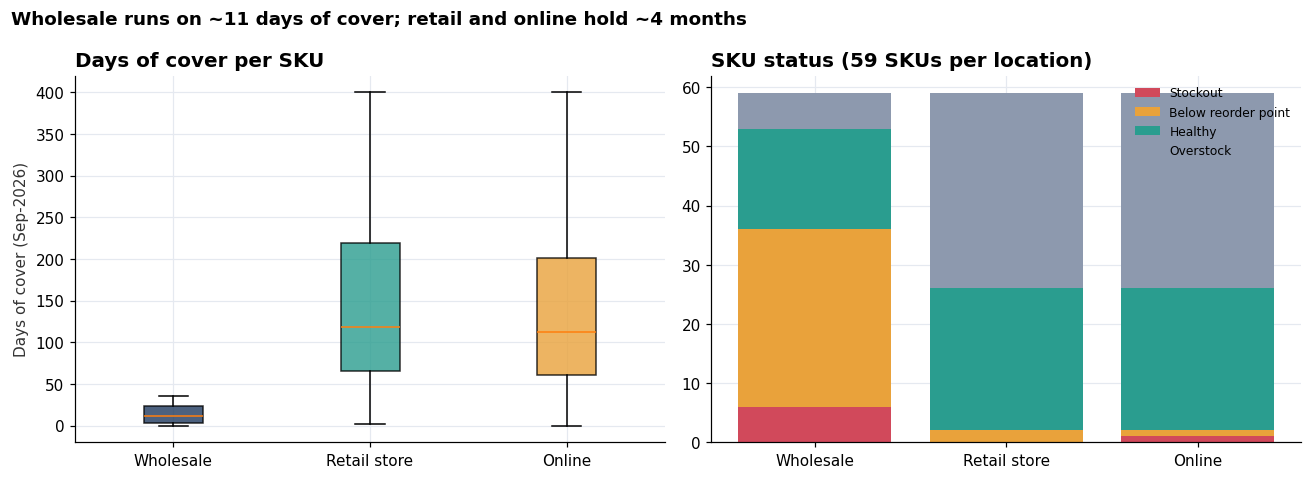

In [15]:
V.inventory_cover_by_location(R['inventory_diag'])

In [16]:
R['inventory_location']

,Location_Name,SKUs,Stock_Value,Excess_Value,Median_Cover_Days,Median_Turns,Stockout_Days_12M,Lost_Units_12M,Overstock_SKUs,Below_ROP_or_Stockout,Excess_Share
0,El-Sharnouby Wholesale Desk,59,"6,430,595.237","1,856,687.060",11.000,24.630,599,"20,083.360",6,36,0.289
1,LEO MODA - Sidi Bishr Store,59,"3,991,966.992","2,662,669.241",118.400,2.965,14,80.590,33,2,0.667
2,LEO MODA Online Store,59,"4,958,511.633","2,959,773.611",112.600,2.867,30,108.510,33,2,0.597


**Observation:** wholesale holds ~11 days of cover and is below reorder point or out of stock on 36 of 59 SKUs; retail and online hold ~4 months and 33 of 59 SKUs each are overstocked.
**Impact:** EGP 7.5M of the EGP 15.4M stock value is excess; wholesale lost an estimated 38.6K units (EGP 1.06M gross profit) to stockouts over three years.
**Action:** forecast-driven replenishment for wholesale; stop buying for retail/online SKUs with >90 days cover (case 4).

## 6. Marketing and web

In [17]:
R['marketing_platform'][['Platform','Spend','Revenue','ROAS','CAC','CTR','CVR','Spend_Share','Revenue_Share']]

,Platform,Spend,Revenue,ROAS,CAC,CTR,CVR,Spend_Share,Revenue_Share
4,WhatsApp / CRM,1546750,"103,572,294.180",66.961,7.295,0.056,0.059,0.106,0.576
0,Google,3890507,"39,952,801.410",10.269,48.259,0.038,0.044,0.267,0.222
3,TikTok,2238109,"10,915,263.710",4.877,104.575,0.023,0.018,0.153,0.061
2,Meta,5437904,"23,742,710.370",4.366,116.068,0.019,0.024,0.373,0.132
1,Influencer,1470706,"1,558,887.600",1.060,471.380,0.012,0.021,0.101,0.009


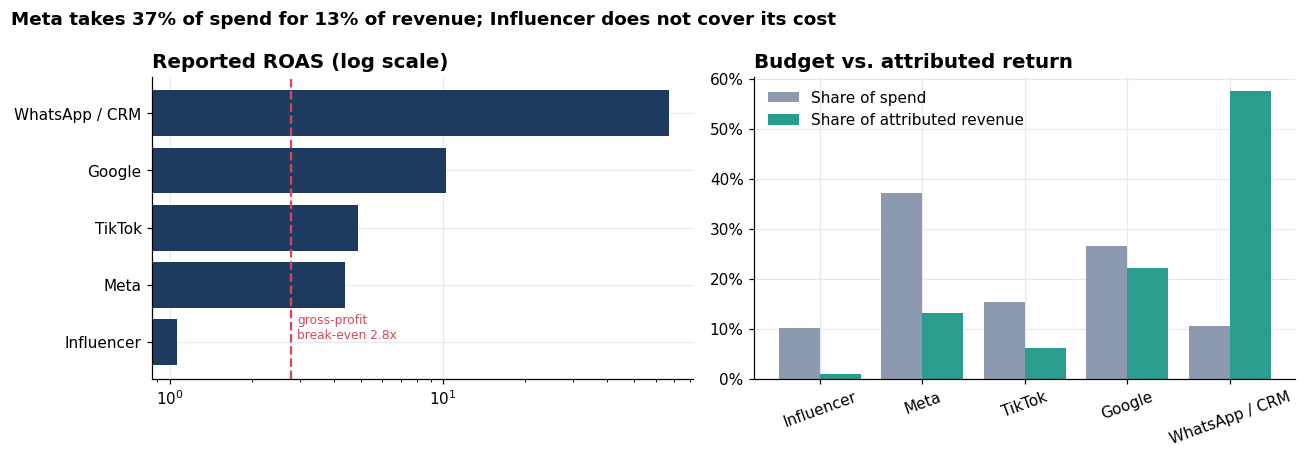

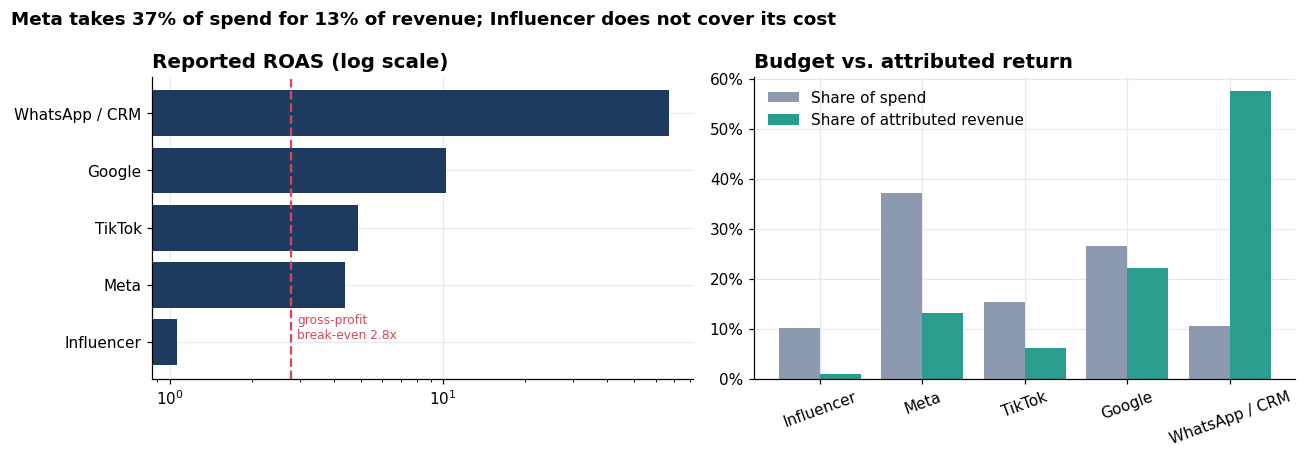

In [18]:
V.platform_roas(R['marketing_platform'], R['breakeven_roas'])

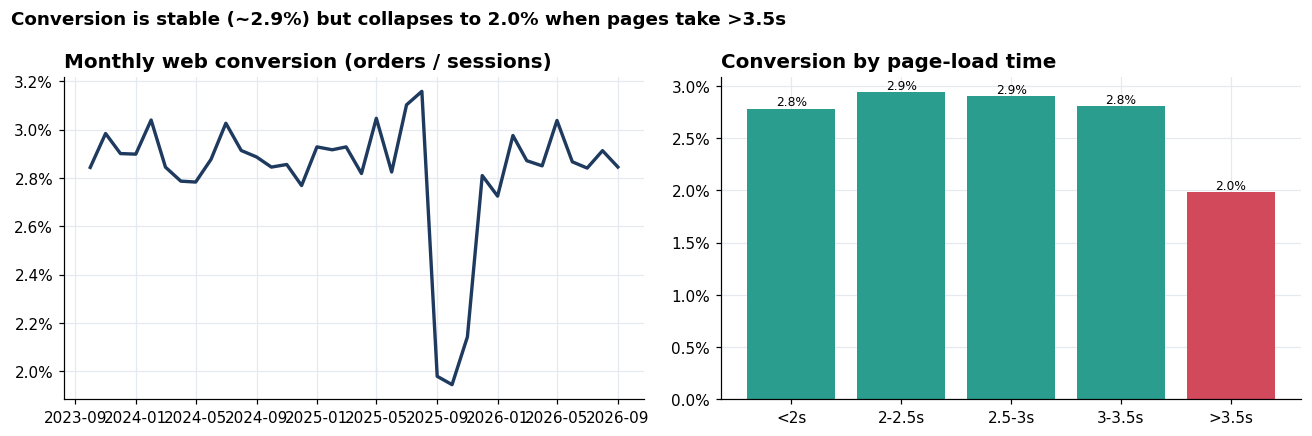

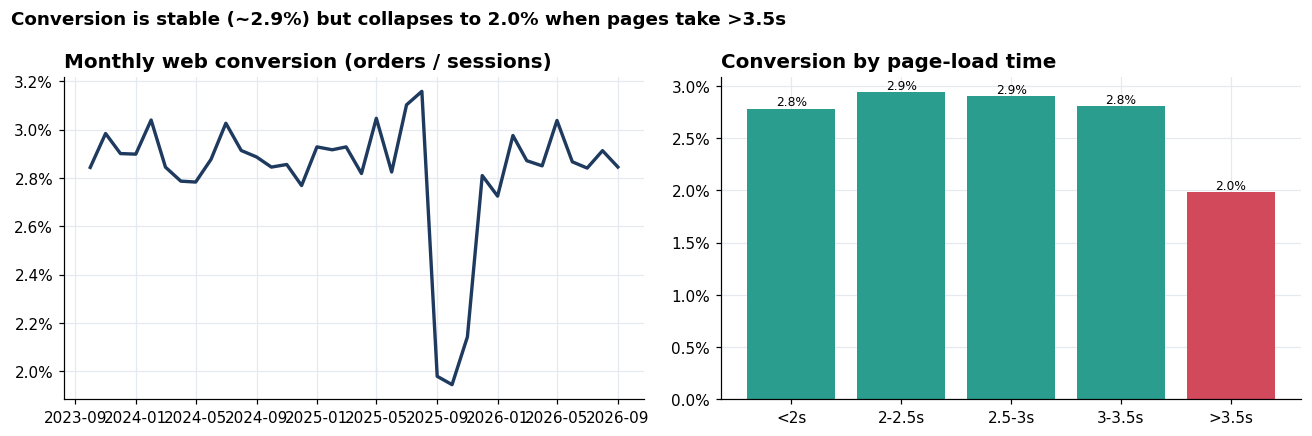

In [19]:
V.web_funnel_panels(R['web_funnel'], R['load_time'])

**Observation:** Meta absorbs 37% of spend for 13% of attributed revenue; Influencer returns 1.06x (CAC EGP 471). Web conversion is stable at ~2.9% but drops to 2.0% on days with pages slower than 3.5s.
**Caveat:** platform-attributed revenue is 5.5x actual online sales, so absolute ROAS is overstated; the **ranking** is reliable. Break-even ROAS on gross profit is 2.8x - Influencer fails under any view.
**Action:** cut Influencer, run incrementality tests before scaling Meta/TikTok, fix page speed.

## 7. Operations: production, quality, printing

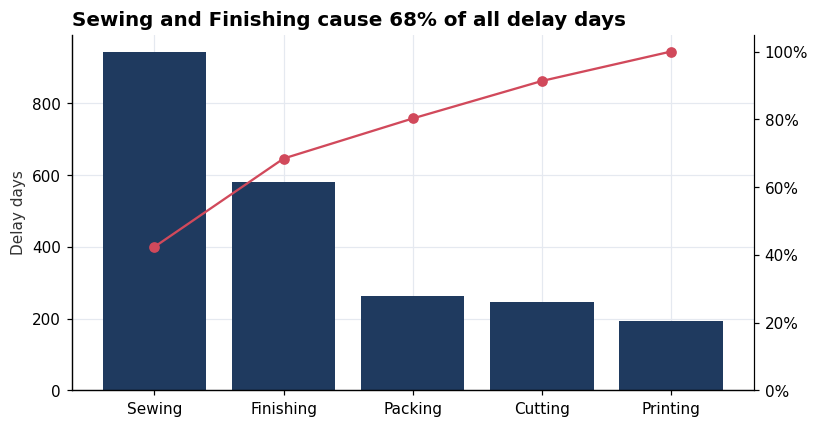

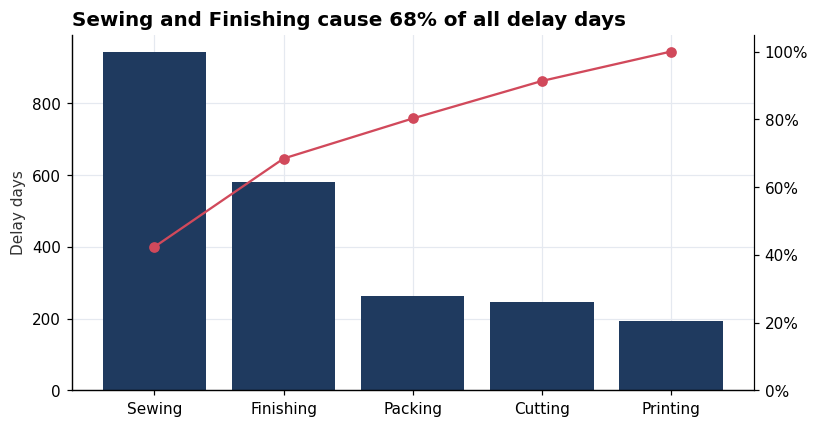

In [20]:
V.bottleneck_pareto_chart(R['bottleneck'])

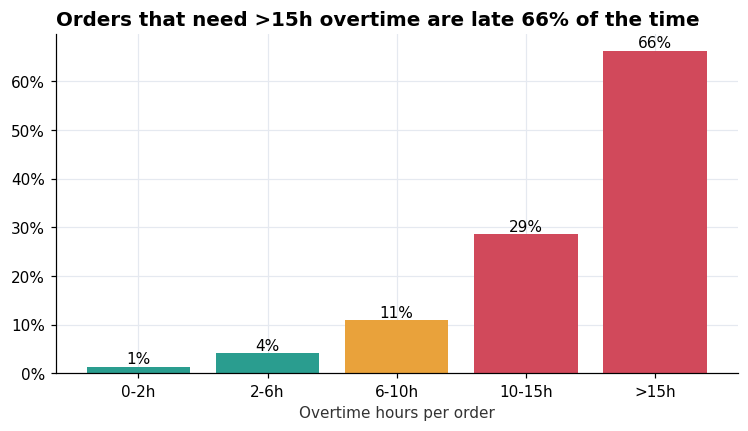

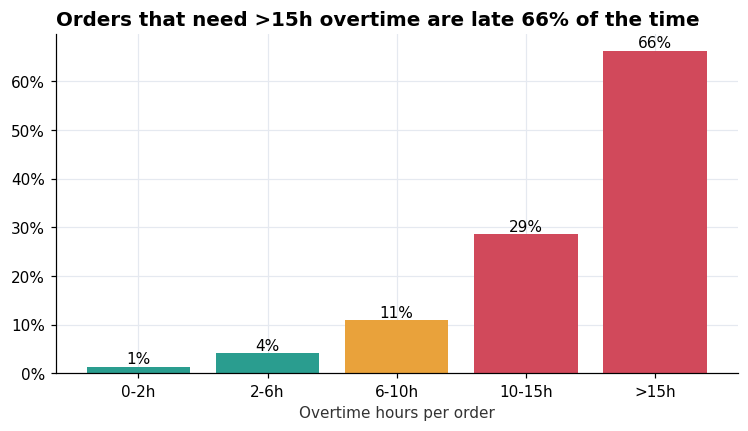

In [21]:
V.overtime_delay_chart(R['overtime'])

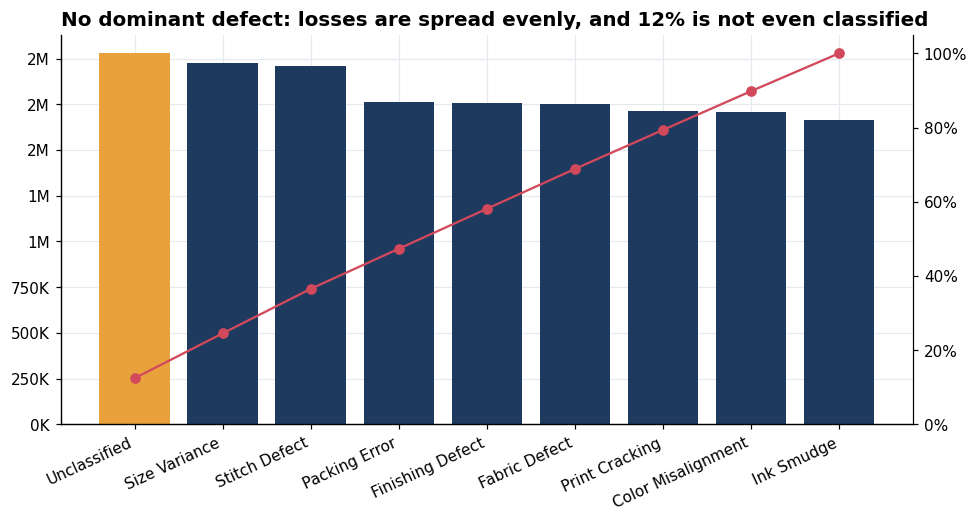

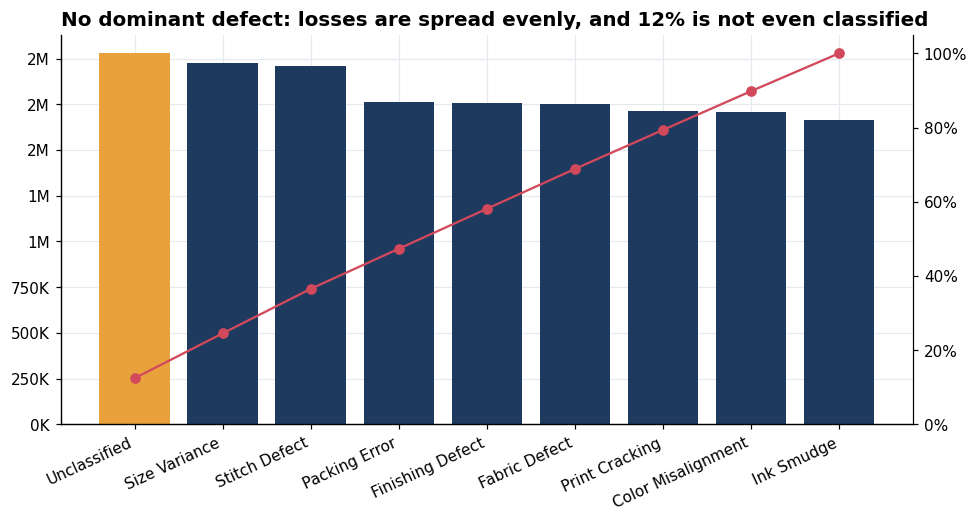

In [22]:
V.defect_pareto_chart(R['defect_pareto'])

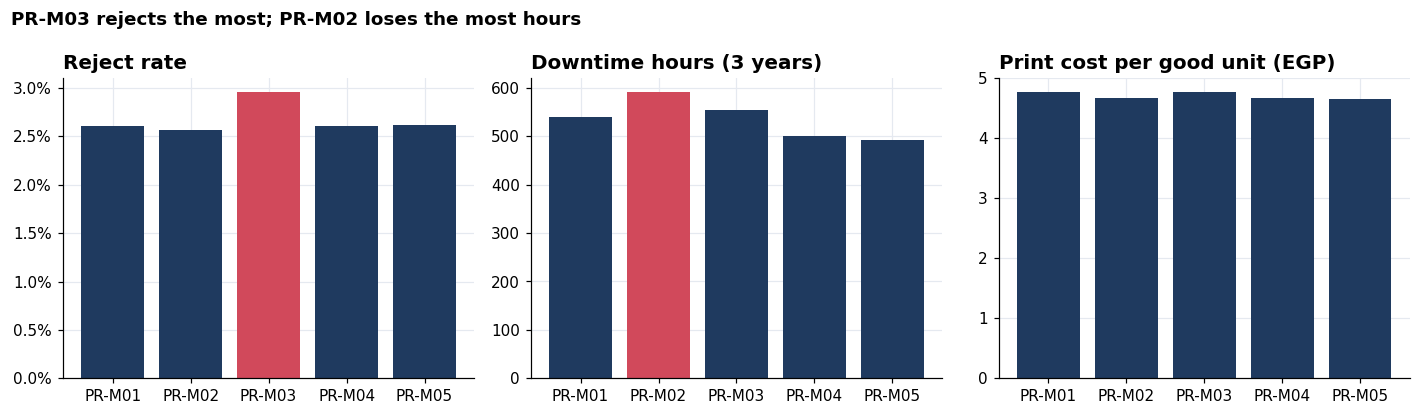

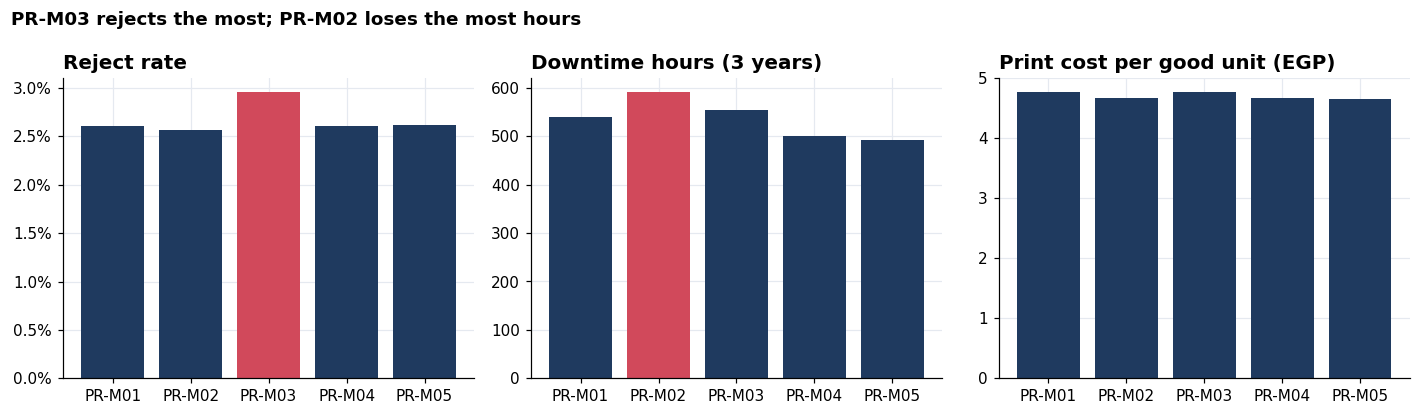

In [23]:
V.printer_priority_chart(R['machines'])

**Production:** Sewing and Finishing cause 68% of delay days; LINE-04 is late 20.3% of the time vs 15.3% elsewhere (chi-square p=0.008); orders needing >15h overtime are late 66% of the time.
**Quality:** no dominant defect - nine defect types each carry 10-12% of the EGP 16.3M QC loss; 12% is unclassified. Estimated cost of poor quality = EGP 20.3M = 31% of gross profit.
**Printing:** PR-M03 has a significantly higher reject rate (3.0% vs 2.6%); PR-M02 has the most downtime (591h); machine-months with more downtime have lower yield (r=-0.21, p=0.004).

## 8. Procurement and suppliers

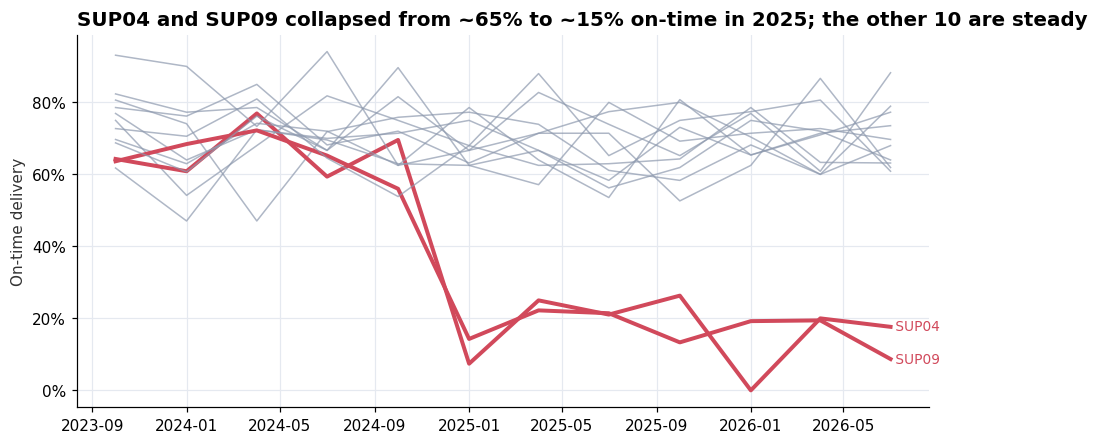

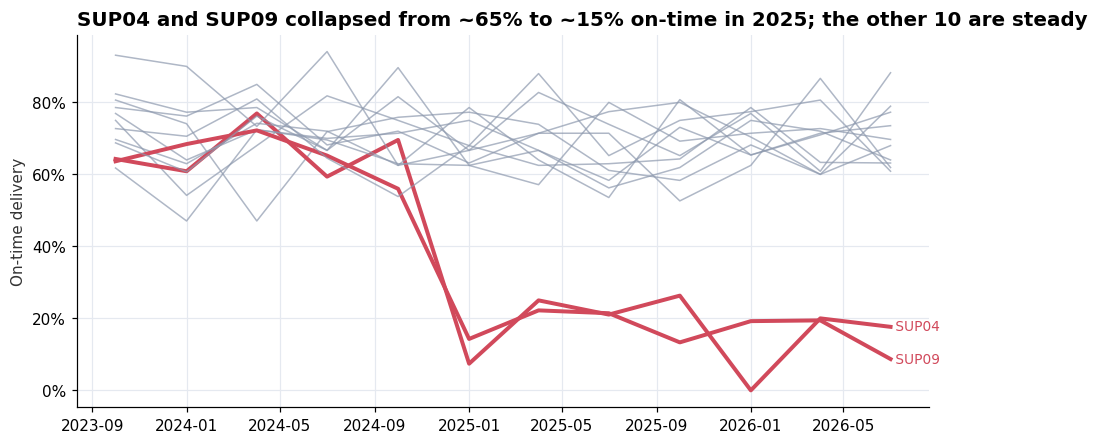

In [24]:
V.supplier_otd_trend_chart(R['supplier_trend'], ['SUP04','SUP09'])

In [25]:
R['supplier_actions']

,Supplier_ID,Category,Contracted,OTD,Avg_Days_Late,Spend,Spend_Share,Reliability,Spend_Tier,Action
8,SUP09,Trims,No,0.346,3.619,"76,331,660.190",0.086,Unreliable,High spend,Replace or dual-source; put under contract
3,SUP04,Printing Consumables,Yes,0.399,2.918,"65,328,364.390",0.074,Unreliable,Lower spend,"Escalate: enforce contract SLA / penalties, qu..."
11,SUP12,Fabric,Yes,0.668,0.544,"61,850,511.200",0.070,Reliable,Lower spend,Monitor: tighten promised dates
5,SUP06,Packaging,Yes,0.679,0.481,"72,353,891.250",0.082,Reliable,Lower spend,Monitor: tighten promised dates
7,SUP08,Trims,No,0.690,0.491,"81,631,567.570",0.092,Reliable,High spend,Monitor: tighten promised dates
6,SUP07,Packaging,Yes,0.693,0.496,"84,758,330.190",0.096,Reliable,High spend,Monitor: tighten promised dates
0,SUP01,Packaging,No,0.703,0.477,"61,340,301.150",0.069,Reliable,Lower spend,Maintain; formalise contract
2,SUP03,Fabric,No,0.722,0.364,"82,890,481.050",0.094,Reliable,High spend,Maintain; formalise contract
4,SUP05,Fabric,No,0.724,0.397,"73,873,102.510",0.083,Reliable,Lower spend,Maintain; formalise contract
10,SUP11,Trims,Yes,0.725,0.446,"76,543,735.690",0.087,Reliable,High spend,Maintain / strategic partner


**Observation:** supplier on-time delivery fell from 74% (2023) to 62%, and it is entirely two suppliers: SUP04 (printing consumables) and SUP09 (trims) went from ~65% to ~15% on-time in 2025 while the other ten stayed at ~70%. They carry 16% of PO spend.
**Action:** enforce SLA on SUP04 (contracted), put SUP09 under contract and dual-source.

## 9. Root-cause view
We tested the chain *suppliers -> material wait -> production delay* and *quality -> returns* on month-over-month changes (to avoid fake trend correlations).

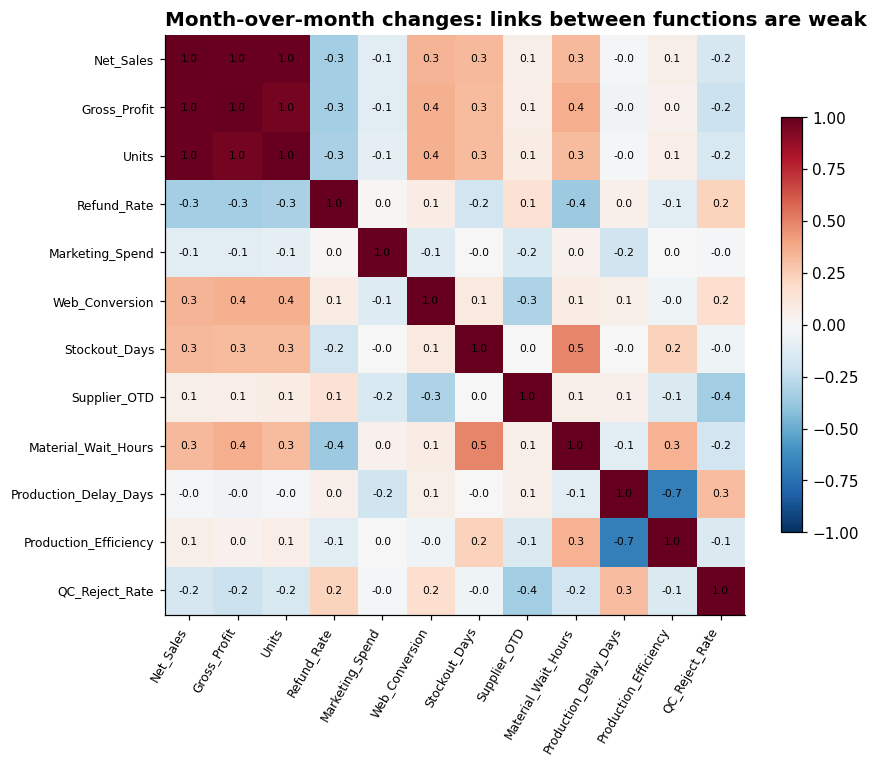

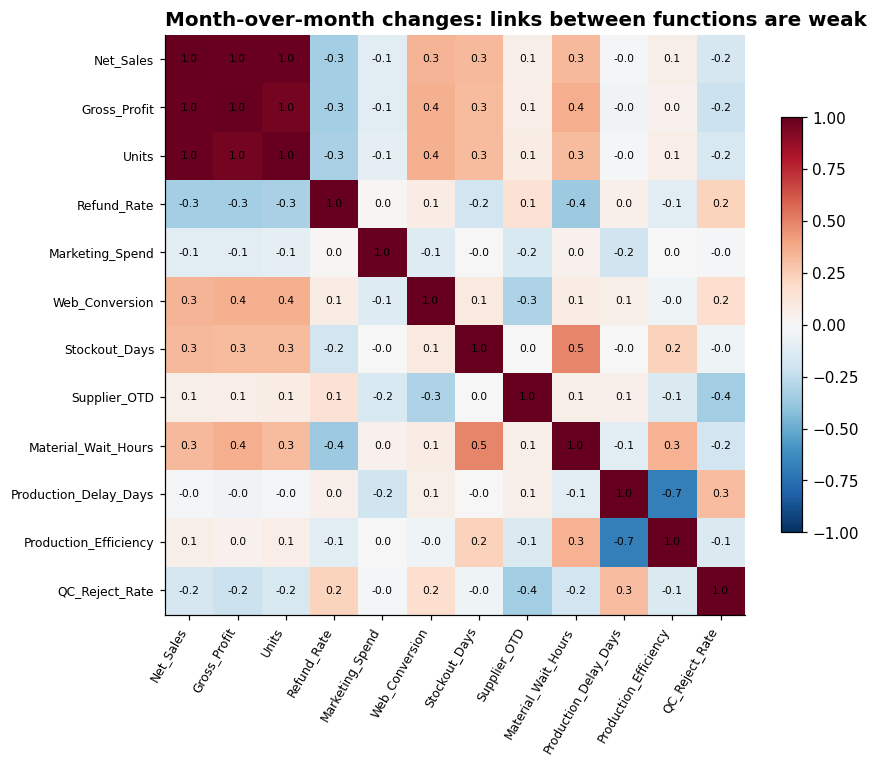

In [26]:
V.chain_corr_heatmap(R['chain_corr'])

In [27]:
R['supplier_to_production_lag']

,x,y,lag_months,pearson_r_on_changes,p_value
0,Supplier_OTD,Production_Delay_Days,0,0.054,0.760
1,Supplier_OTD,Production_Delay_Days,1,0.141,0.428
2,Supplier_OTD,Production_Delay_Days,2,0.088,0.625
3,Supplier_OTD,Production_Delay_Days,3,-0.076,0.678


**Honest finding:** supplier lateness does **not** statistically explain production delay (r=0.05, p=0.76; no lagged effect). Production delay is an *internal* problem (Sewing/Finishing capacity, LINE-04, overtime). Supplier decay is a real but separate, concentrated risk that has not yet hit output.
Quality does connect to customers for fabric/stitching defects (product-level r=0.33, p=0.011) but not for print defects (r=0.15, n.s.); the largest return reason (36%) is size/fit, which is not a factory issue.